### Your name:

<pre> Shamir Alavi </pre>

### Collaborators:

<pre> None </pre>


In [1]:
import numpy as np
import pandas as pd

# to make this notebook's output stable across runs
np.random.seed(123)

# To plot pretty figures
%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12


### Classification

Q1. Build a classification model for the default of credit card clients dataset. More info here:
https://archive.ics.uci.edu/ml/datasets/default+of+credit+card+clients

- Explore the data
- Make sure you build a full data pipeline
- Do you require any data pre-processing? Are all the features useful? (Use only raw features)
- set the random seed to 123 (For splitting or any other random algorithm)
- Split data into training (80%) and testing (20%)
- Follow similar procedure as the one for week 2 (End-to-end Machine Learning Project). Remember apendix B
- Study the ROC Curve, decide threshold
- Use 2 classifiers.
    - Random Forest
        - tune only: n_estimators: {4, 5, 10, 20, 50} 
    - KNN Classfier 
        - tune only: n_neighbors: {3, 5, 10, 20} 
    - Which one performs better in the cross validation?
    
http://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html
http://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html

- Cross-validation with 5-folds

- Other paramenters -> Use default

In [19]:
def plot_distribution(df, col, x_label):
    df[col].value_counts().sort_index().plot(
        kind="bar",
        xlabel=x_label,
        ylabel="Number of clients",
        title="Distribution of clients by " + x_label
    )
    plt.tight_layout()
    plt.show()

In [2]:
### Your code here

## Feel free to use multiple cells

import os
import pandas as pd

DATA_PATH = os.path.join('..', 'data')

def load_credit_card_default_data(data_path=DATA_PATH):
    csv_path = os.path.join(data_path, "default_of_credit_card_clients.csv")
    return pd.read_csv(csv_path)

cc_original = load_credit_card_default_data()


In [ ]:
cc_original = cc_original.drop(cc_original.columns[0], axis=1)
cc_original.head()

In [ ]:
cc_original.info()

In [5]:
# 1 = male; 2 = female
cc_original["SEX"].value_counts()   # imbalanced

SEX
2    18112
1    11888
Name: count, dtype: int64

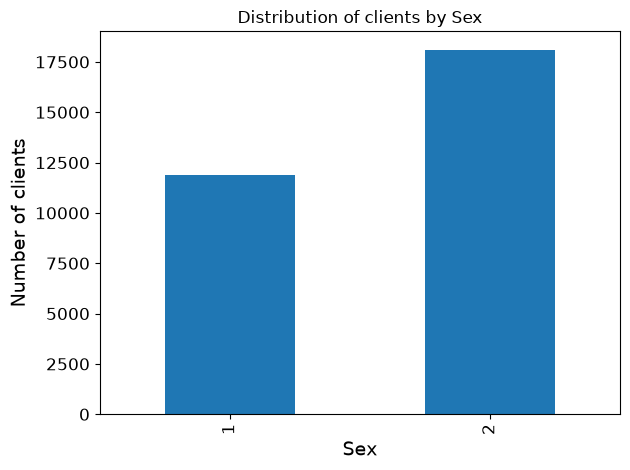

In [21]:
# split sex into categorcal values
cc_original["sex"] = pd.cut(cc_original["SEX"], bins=[0,1,np.inf], labels=[1,2])
plot_distribution(cc_original, "sex", "Sex")

In [6]:
# 1 = graduate school; 2 = university; 3 = high school; 4 = others
cc_original["EDUCATION"].value_counts()   # imbalanced

EDUCATION
2    14030
1    10585
3     4917
5      280
4      123
6       51
0       14
Name: count, dtype: int64

In [7]:
# consolidate other categories into category 4
cc_original["EDUCATION"] = cc_original["EDUCATION"].replace({
    0: 4,
    5: 4,
    6: 4,
})

In [8]:
cc_original["EDUCATION"].value_counts()

EDUCATION
2    14030
1    10585
3     4917
4      468
Name: count, dtype: int64

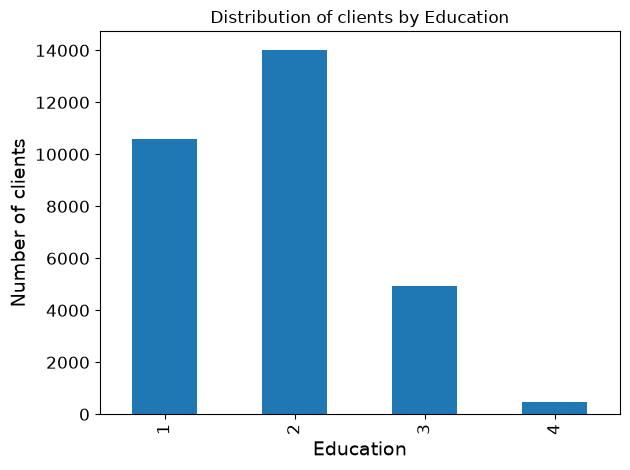

In [24]:
# split education into categorcal values
cc_original["education"] = pd.cut(cc_original["EDUCATION"], bins=[0,1,2,3,np.inf], labels=[1,2,3,4])
plot_distribution(cc_original, "education", "Education")

In [10]:
# 1 = married; 2 = single; 3 = others

cc_original["MARRIAGE"] = cc_original["MARRIAGE"].replace({
    0: 3
})

cc_original["MARRIAGE"].value_counts()   # imbalanced

MARRIAGE
2    15964
1    13659
3      377
Name: count, dtype: int64

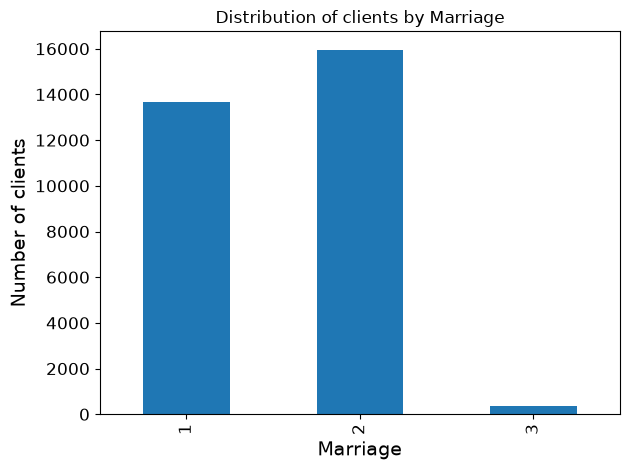

In [25]:
# split marriage into categorcal values
cc_original["marriage"] = pd.cut(cc_original["MARRIAGE"], bins=[0,1,2,np.inf], labels=[1,2,3])
plot_distribution(cc_original, "marriage", "Marriage")

In [ ]:
cc_original["AGE"].value_counts()   # imbalanced

In [ ]:
cc_original["AGE"].describe()

count    30000.000000
mean        35.485500
std          9.217904
min         21.000000
25%         28.000000
50%         34.000000
75%         41.000000
max         79.000000
Name: AGE, dtype: float64

In [ ]:
cc_original["AGE"].hist(bins=10, figsize=(20,15))
# save_fig("attribute_histogram_plots")

plt.show()

In [11]:
# split age into categorcal values
cc_original["age_group"] = pd.cut(cc_original["AGE"], bins=[0,29,39,49,59,69,np.inf], labels=[1,2,3,4,5,6])

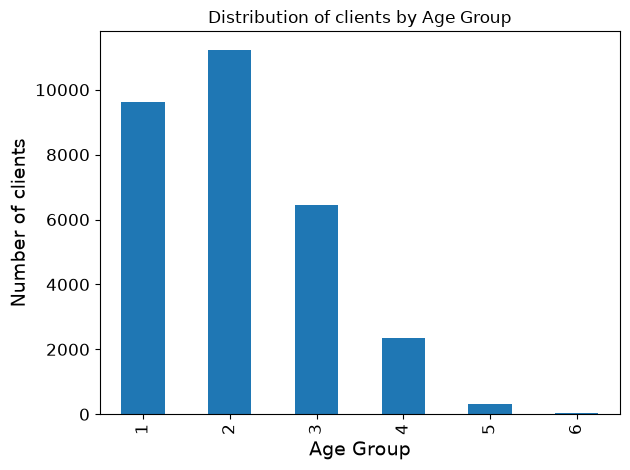

In [20]:
plot_distribution(cc_original, "age_group", "Age Group")

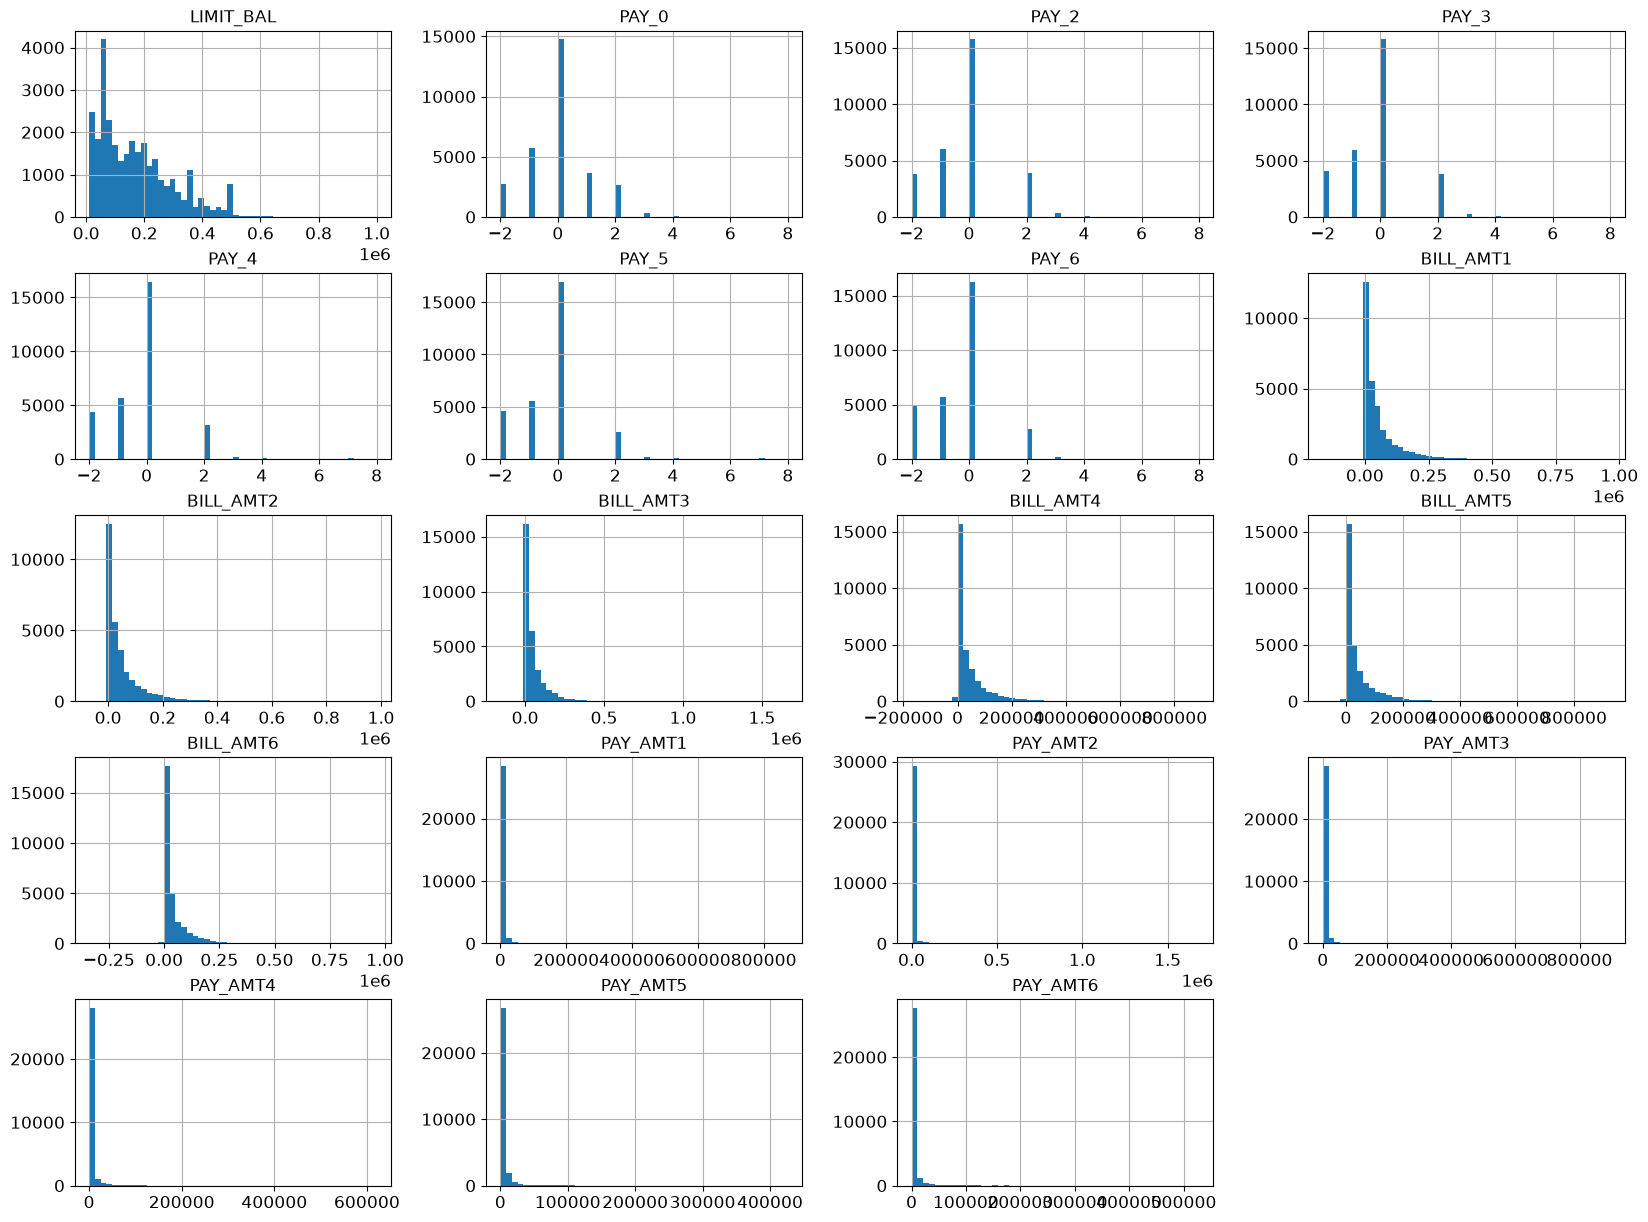

In [28]:
columns = [
    "LIMIT_BAL", "PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6",
    "BILL_AMT1", "BILL_AMT2", "BILL_AMT3", "BILL_AMT4", "BILL_AMT5", "BILL_AMT6",
    "PAY_AMT1", "PAY_AMT2", "PAY_AMT3", "PAY_AMT4", "PAY_AMT5", "PAY_AMT6",
]

cc_original[columns].hist(bins=50, figsize=(20, 15))
plt.show()

In [26]:
cc_original.columns

Index(['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2',
       'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2',
       'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1',
       'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6',
       'default payment next month', 'age_group', 'sex', 'education',
       'marriage'],
      dtype='str')

#### Conclusions?

Explain your results and choices

Q2. (Optional) Write a function that can shift an MNIST image in any direction (left, right, up, or down) by one pixel. Then, for each image in the training set, create four shifted copies (one per direction) and add them to the training set. Finally, train your best model on this expanded training set and measure its accuracy on the test set. You should observe that your model performs even better now! This technique of artificially growing the training set is called data augmentation or training set expansion. 

### Conclusions


### Submit your notebook

Submit your solution here
https://goo.gl/forms/VKD7Zwu54oHjutDc2
Make sure you rename your notebook to    
W3_UTORid.ipynb    
Example W3_adfasd01.ipynb
